# Ce Notebook contient les principales étapes de l'analyse ainsi que les résultats

## Importation des modules

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import nbformat as nb

## Importation des bases de données:

In [35]:
# Importation de la base 1 (NAVCO 2.1)
navco = pd.read_excel("Data/base2-1.xls")

# Importation de la base de population
pop = pd.read_csv("Data/population.csv", sep=",")

data_clean = False

## Nettoyage des données

In [36]:
if data_clean == False:
    with open("Cleanup.ipynb", "r", encoding="utf-8") as f:
        cleanup_nb = nb.read(f, as_version=4)

    # Use the current notebook's namespace
    namespace = globals()

    # Execute all code cells sequentially
    for cell in cleanup_nb.cells:
        if cell.cell_type == "code":
            exec(cell.source, namespace)  # noqa: S102
    
    data_clean = True

2717 2717
_merge
both          2699
left_only       18
right_only       0
Name: count, dtype: int64
     location  year
South Vietnam  1958
South Vietnam  1959
South Vietnam  1960
South Vietnam  1961
South Vietnam  1962
South Vietnam  1963
South Vietnam  1964
South Vietnam  1965
South Vietnam  1966
        Tibet  1956
        Tibet  1957
        Tibet  1958
        Tibet  1959
        Tibet  1987
        Tibet  1988
        Tibet  1989
      location  year  total_part_clean  Population  pourcent_part
0   Madagascar  1991          400000.0  12421413.0       3.220246
1   Madagascar  1992               NaN  12800870.0            NaN
2   Madagascar  1993               NaN  13197353.0            NaN
3     Djibouti  1991            3000.0    631096.0       0.475363
4     Djibouti  1992            4500.0    626016.0       0.718831
5     Djibouti  1993            4500.0    614247.0       0.732604
6     Djibouti  1994            4500.0    626717.0       0.718027
7  Afghanistan  1979           1

## Analyses sur le lien entre taux de participation et réussite du mouvement

In [37]:
# Calcul de la corrélation de Spearman

spearman_corr, p_value = stats.spearmanr( df_pc_pop["pourcent_part"], df_pc_pop["progress2"]) # corrélation de Spearman

print(f"Corr de Spearman : {spearman_corr:.4f}") #ici on regarde année par année les mouvements donc certains sont représentés plusieurs fois
print(f"P-value : {p_value:.4e}")

Corr de Spearman : 0.2538
P-value : 1.2482e-34


In [38]:
# Prise en compte uniquement du pic de participation

mouv_peak = (
    navco_pop.sort_values(["id", "year"])
    .groupby("id")
    .agg(
        location=("location", "first"),
        pic_pourcent=("pourcent_part", "max"),      # pic de participation
        success=("success", "last"),                # dernière ligne = résultat final
    )
    .reset_index()
)

print(mouv_peak.shape)                      

print("Mouvements sans pic calculable :", mouv_peak["pic_pourcent"].isna().sum())

(384, 4)
Mouvements sans pic calculable : 20


In [39]:
mouv_peak = mouv_peak.dropna(subset=["pic_pourcent"]).copy()    
mouv_peak["tranche"] = pd.qcut(mouv_peak["pic_pourcent"], q=10, duplicates="drop")
print(mouv_peak.groupby("tranche", observed=True)["success"].agg(n="count", taux="mean"))

mouv_peak["au_dessus"] = mouv_peak["pic_pourcent"] >= 3.5
print(mouv_peak.groupby("au_dessus")["success"].agg(n="count", taux="mean"))
print(mouv_peak[(mouv_peak["au_dessus"]) & (mouv_peak["success"] == 0)])   # les exceptions

                       n      taux
tranche                           
(-0.0009694, 0.0139]  37  0.027027
(0.0139, 0.0428]      36  0.194444
(0.0428, 0.0894]      36  0.194444
(0.0894, 0.158]       37  0.378378
(0.158, 0.259]        36  0.361111
(0.259, 0.524]        36  0.444444
(0.524, 0.896]        37  0.540541
(0.896, 1.85]         36  0.472222
(1.85, 4.664]         36  0.555556
(4.664, 33.751]       37  0.648649
             n      taux
au_dessus               
False      321  0.348910
True        43  0.627907
      id                      location  pic_pourcent  success  \
18    21                      Pakistan      4.276359        0   
21    24                        Panama     32.580662        0   
58    64                Czechoslovakia     24.441341        0   
67    74                  East Germany     10.875476        0   
76    83                    Madagascar      5.356130        0   
151  164                     Palestine     33.750774        0   
171  184           Yemen 

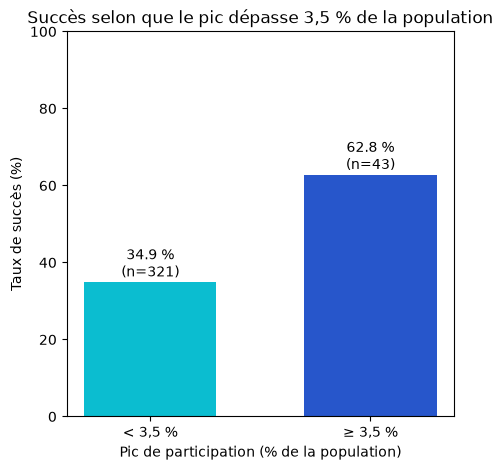

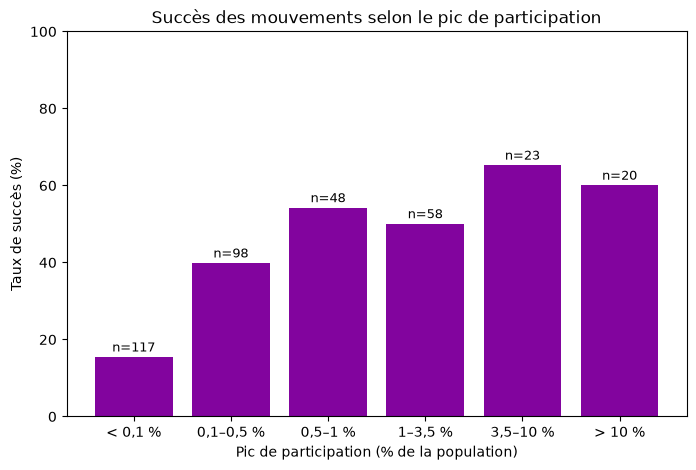

In [49]:
tab1 = mouv_peak.groupby("au_dessus")["success"].agg(n="count", taux="mean")
labels = ["< 3,5 %", "≥ 3,5 %"]          # False puis True, dans cet ordre

fig, ax = plt.subplots(figsize=(5, 5))
ax.bar(labels, tab1["taux"] * 100, color=["#0BBDD0", "#2756CB"], width=0.6)

for i, (t, n) in enumerate(zip(tab1["taux"], tab1["n"])):  #pour afficher l'effectif de chaque barre
    ax.text(i, t * 100 + 1.5, f"{t*100:.1f} %\n(n={n})", ha="center", fontsize=10)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès selon que le pic dépasse 3,5 % de la population")
ax.set_ylim(0, 100)
plt.savefig("graph_seuil_3_5.png", dpi=200, bbox_inches="tight")
plt.show()

bins   = [0, 0.1, 0.5, 1, 3.5, 10, 35]
labels = ["< 0,1 %", "0,1–0,5 %", "0,5–1 %", "1–3,5 %", "3,5–10 %", "> 10 %"]

mouv_peak["classe"] = pd.cut(mouv_peak["pic_pourcent"], bins=bins,
                             labels=labels, include_lowest=True)
tab2 = mouv_peak.groupby("classe", observed=True)["success"].agg(n="count", taux="mean")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(tab2.index, tab2["taux"] * 100, color="#82049E")
for i, (t, n) in enumerate(zip(tab2["taux"], tab2["n"])):
    ax.text(i, t * 100 + 1.5, f"n={n}", ha="center", fontsize=9)

ax.set_ylabel("Taux de succès (%)")
ax.set_xlabel("Pic de participation (% de la population)")
ax.set_title("Succès des mouvements selon le pic de participation")
ax.set_ylim(0, 100)
plt.savefig("graph_participation_succes.png", dpi=200, bbox_inches="tight")
plt.show()

## Etude de l'impact de la violence / non-violence

In [40]:
# Classification des campagnes :
camp = (navco2.groupby("id")
        .agg(camp_name=("camp_name", "first"),
             location=("location", "first"),
             debut=("start_year", "first"),
             fin=("end_year", "first"),
             duree=("camp_duration", "first"),
             nb_annees=("year", "count"),
             violente_moy=("violente", "mean"),
             intensite_max=("camp_confl_intensity", "max"),
             intensite_moy=("camp_confl_intensity", "mean"),
             repression_max=("repression", "max"))
        .reset_index())
camp["violente"] = (camp["violente_moy"] > 0.5).astype(int)
camp["mixte"] = camp["violente_moy"].between(0.01, 0.99)

In [41]:
# Issue de chaque campagne
derniere = base.groupby("id").tail(1).set_index("id")
camp["annee_finale"] = camp["id"].map(derniere["year"])
camp["progress_final"] = camp["id"].map(derniere["progress2"])
camp["status"] = camp["id"].map(derniere["status"])
camp["success"] = camp["id"].map(base.groupby("id")["success"].max())

camp["issue"] = np.select(
    [camp["success"] == 1, camp["status"] == 0],
    ["succes", "echec"],
    default="en_cours")

In [42]:
# Méthode et succès :

# On exclut les campagnes en cours, dont l'issue est inconnue
net = camp[camp["issue"] != "en_cours"].copy()

print("Campagnes au total :", len(camp))
print("Campagnes en cours (exclues) :", (camp["issue"] == "en_cours").sum())
print("Campagnes retenues :", len(net))
print("dont mixtes :", net["mixte"].sum())

tab = net.groupby("violente")["success"].agg(taux="mean", succes="sum", n="count").round(3)
print("\n", tab)

ct = pd.crosstab(net["violente"], net["success"])
print("\n", ct)
odds, p = stats.fisher_exact(ct)
print(f"\nOdds ratio = {odds:.2f}, p = {p:.2e}")

d = net.dropna(subset=["intensite_max"])
print("\n", pd.crosstab(d["violente"], d["intensite_max"]))
print(d.groupby(["violente", "intensite_max"])["success"].agg(taux="mean", n="count").round(3))

Campagnes au total : 384
Campagnes en cours (exclues) : 53
Campagnes retenues : 331
dont mixtes : 21

            taux  succes    n
violente                    
0         0.592      87  147
1         0.326      60  184

 success     0   1
violente         
0          60  87
1         124  60

Odds ratio = 0.33, p = 1.56e-06

 intensite_max  0.0  1.0  2.0  3.0
violente                         
0               79   38   16   14
1               66   26   25   65
                         taux   n
violente intensite_max           
0        0.0            0.544  79
         1.0            0.684  38
         2.0            0.562  16
         3.0            0.643  14
1        0.0            0.318  66
         1.0            0.346  26
         2.0            0.360  25
         3.0            0.323  65


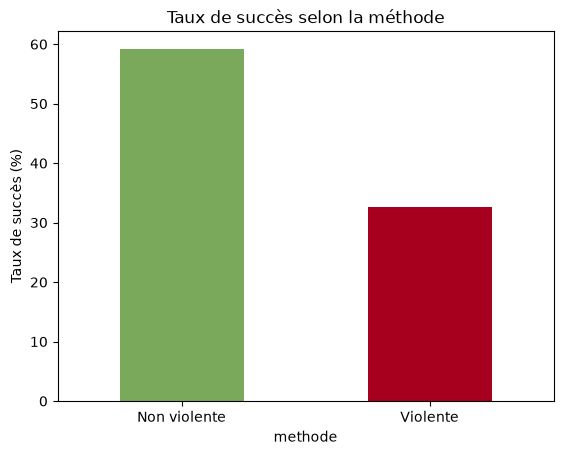

In [43]:
# Graphiques

df = camp[camp["issue"] != "en_cours"].copy() # enlever les lignes avec valeur "en_cours" car leur résultat définitif n'est pas encore connu
df["methode"] = df["violente"].map({0: "Non violente", 1: "Violente"}) # nouvelle colonne avec la méthode (violente/non violente)

# Graph 1 : succès selon la méthode
(df.groupby("methode")["success"].mean() * 100).plot(kind="bar", color=["#7AA95C", "#A7001E"])
plt.ylabel("Taux de succès (%)")
plt.title("Taux de succès selon la méthode")
plt.xticks(rotation=0)
plt.savefig("graph1_succes_methode.png", dpi=200, bbox_inches="tight")
plt.show()